# A9 crop water balance: running the model and evaluating it

Runs the FAO-56 daily water balance step by step for one crop and season, then for all crops and LGA-years, checks it, and saves the outputs to `data/processed/models/a9/`. A9 is a physical model, not a trained one: nothing is fitted to data. Its coefficients come from FAO-56 tables (`config/crops.yaml`) and its soil water from A8 (`a8_soil_water.ipynb`, run first), so it is checked against SMAP, MODIS ET and a Hargreaves baseline rather than cross-validated.

Science functions: `model/water_balance.py`. Run: `model/water_pipeline.py`. Write-up: `docs/model-results.md`.

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import experiments
from model import water_balance as wb
from model import water_pipeline as wp
from model.experiments import log_experiments
from model.io import write_csv, write_json
from model.settings import load_crop_config, load_model_config

## 1. Load settings, crop parameters and daily inputs

In [4]:
# Load settings, the seven crops' FAO-56 parameters (config/crops.yaml), the A5 season
# types, and daily inputs for every LGA: CHIRPS rain, POWER ET0, A2 planting dates and the
# soil water A8 chose. Then show each crop's season length, mid-season Kc, roots and p.
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
crops = load_crop_config().crops
types = pd.read_csv(cfg.paths.output_dir / "a5" / "a5_lga_year_types.csv")
inputs = wp.load_inputs(cfg, sorted(types["lga"].unique()))
soil_method = pd.read_csv(cfg.paths.soil)["method"].iloc[0]  # chosen in a8_soil_water
pd.DataFrame(
    {
        name: {
            "season days": c.stages_days.total,
            "Kc mid": c.kc.mid,
            "max roots (m)": c.root_depth_max_m,
            "p": c.depletion_fraction_p,
        }
        for name, c in crops.items()
    }
).T

,season days,Kc mid,max roots (m),p
maize,125.0,1.20,1.7,0.55
sorghum,125.0,1.05,2.0,0.55
millet,105.0,1.00,2.0,0.55
soybean,85.0,1.15,1.3,0.50
cowpea,100.0,1.05,1.0,0.45
groundnut,130.0,1.15,1.0,0.50
sesame,110.0,1.10,1.5,0.60


## 2. The pieces for one crop: Kc curve and root growth (FAO-56 Figure 25, Table 22)

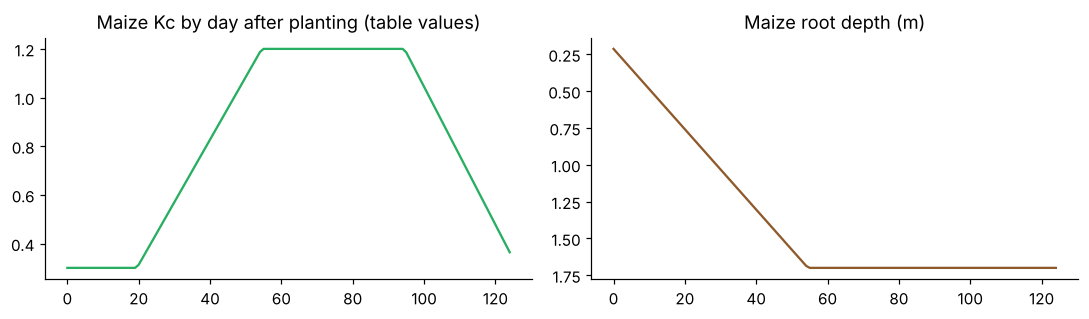

In [5]:
# The two growth curves for maize: Kc by day after planting (FAO-56 Figure 25, Eq. 66) and
# root depth growing from the initial to the maximum depth.
maize = crops["maize"]
lengths = tuple(maize.stages_days.model_dump().values())
w = wb.kc_weights(lengths)
kc_table = maize.kc.ini * w[0] + maize.kc.mid * w[1] + maize.kc.end * w[2]  # FAO-56 Eq. 66
roots = wb.root_depth_m(lengths, cfg.water_balance.root_depth_initial_m, maize.root_depth_max_m)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(kc_table, color="#27ae60")
axes[0].set_title("Maize Kc by day after planting (table values)")
axes[1].plot(roots, color="#8e5a2b")
axes[1].invert_yaxis()
axes[1].set_title("Maize root depth (m)")
plt.tight_layout()

## 3. One season traced as a worked example: Zaria maize, 2017 (section 4 runs all 23 LGAs)

plant_date        2017-06-30 00:00:00
water_need_mm               401.44506
water_used_mm               401.44506
season_rain_mm             677.925665
stress_days                         0
fits_season                     False
Name: 1026, dtype: object

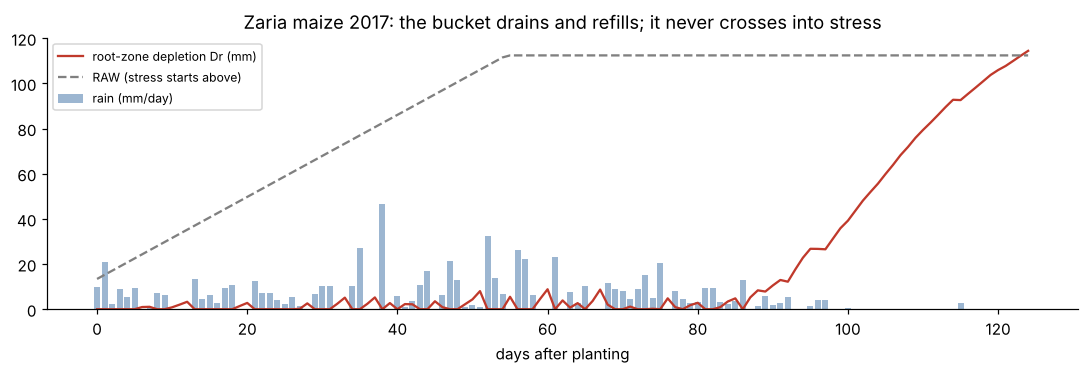

In [6]:
# Worked example: run maize for every LGA-year, then pull out Zaria 2017 and plot its daily
# rain and root-zone depletion against RAW, the point where stress begins.
rows, result, taw = wp.run_crop("maize", maize, inputs, cfg)
i = rows.index[(rows["lga"] == "Zaria") & (rows["year"] == 2017)][0]
windows, complete = wp.season_windows(inputs, maize.stages_days.total)
rain = windows["rain_mm"][complete][i]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(rain)), rain, color="#3b6ea5", alpha=0.5, label="rain (mm/day)")
ax.plot(result.depletion_mm[i], color="#c0392b", label="root-zone depletion Dr (mm)")
ax.plot(
    taw[i] * maize.depletion_fraction_p, color="grey", ls="--", label="RAW (stress starts above)"
)
ax.set_xlabel("days after planting")
ax.legend(fontsize=8)
ax.set_title("Zaria maize 2017: the bucket drains and refills; it never crosses into stress")
plt.tight_layout()
rows.loc[
    i,
    [
        "plant_date",
        "water_need_mm",
        "water_used_mm",
        "season_rain_mm",
        "stress_days",
        "fits_season",
    ],
]

## 4. Run every crop over every LGA-year, with the Hargreaves baseline

In [7]:
# The full run: every crop, every LGA, every year (1981 to 2025), with Penman-Monteith ET0
# and the Hargreaves baseline. The table summarizes each crop over all 23 LGAs.
runs = wp.run_all(crops, inputs, cfg)
share = cfg.water_balance.shortfall_share
all_rows = wp.mark_short(pd.concat([r.rows for r in runs.values()], ignore_index=True), share)
hg_rows = wp.mark_short(pd.concat([r.hargreaves for r in runs.values()], ignore_index=True), share)
all_rows = all_rows.merge(types[["lga", "year", "season_type"]], on=["lga", "year"], how="left")
pd.DataFrame(
    {
        "LGA-years": all_rows.groupby("crop").size(),
        "need (mm, median)": all_rows.groupby("crop")["water_need_mm"].median().round(0),
        "rain (mm, median)": all_rows.groupby("crop")["season_rain_mm"].median().round(0),
        "short, Penman-Monteith": all_rows.groupby("crop")["ran_short"].mean().round(3),
        "short, Hargreaves": hg_rows.groupby("crop")["ran_short"].mean().round(3),
        "fits rainy season": all_rows.groupby("crop")["fits_season"].mean().round(3),
    }
)

,LGA-years,"need (mm, median)","rain (mm, median)","short, Penman-Monteith","short, Hargreaves",fits rainy season
crop,,,,,,
cowpea,1035,284.0,735.0,0.000,0.000,0.975
groundnut,1035,412.0,968.0,0.054,0.051,0.826
maize,1035,374.0,935.0,0.003,0.003,0.856
millet,1035,282.0,779.0,0.000,0.000,0.952
sesame,1035,318.0,822.0,0.000,0.000,0.929
sorghum,1035,343.0,935.0,0.002,0.001,0.856
soybean,1035,288.0,604.0,0.003,0.001,0.996


crop,cowpea,groundnut,maize,millet,sesame,sorghum,soybean
lga,,,,,,,
Birnin Gwari,1.00,0.93,0.96,1.00,1.00,0.96,1.00
Chikun,1.00,0.93,0.93,1.00,1.00,0.93,1.00
Giwa,0.98,0.71,0.76,0.98,0.91,0.76,1.00
Igabi,1.00,0.73,0.76,1.00,0.98,0.76,1.00
Ikara,0.84,0.40,0.47,0.76,0.67,0.47,1.00
Jaba,1.00,1.00,1.00,1.00,1.00,1.00,1.00
Jema'a,1.00,1.00,1.00,1.00,1.00,1.00,1.00
Kachia,1.00,1.00,1.00,1.00,1.00,1.00,1.00
Kaduna North,1.00,0.84,0.91,1.00,0.98,0.91,1.00


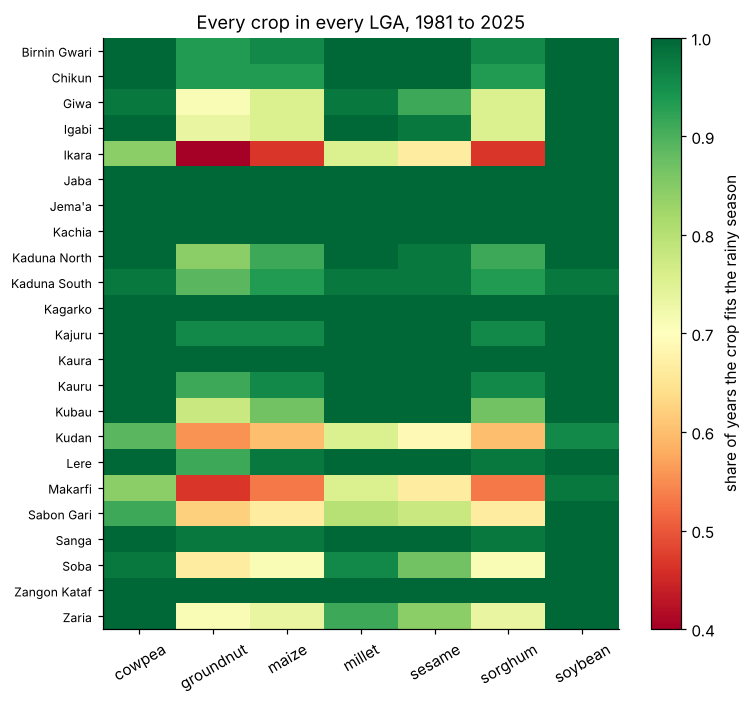

In [8]:
# All 23 LGAs: share of years each crop finishes inside the rainy season.
per_lga = all_rows.groupby(["lga", "crop"])["fits_season"].mean().unstack()
fig, ax = plt.subplots(figsize=(7, 6.5))
im = ax.imshow(per_lga, cmap="RdYlGn", vmin=0.4, vmax=1, aspect="auto")
ax.set_xticks(range(per_lga.shape[1]), per_lga.columns, rotation=30)
ax.set_yticks(range(per_lga.shape[0]), per_lga.index, fontsize=8)
fig.colorbar(im, label="share of years the crop fits the rainy season")
ax.set_title("Every crop in every LGA, 1981 to 2025")
plt.tight_layout()
per_lga.round(2)

## 5. Timing is the risk: fit inside the rainy season by A5 season type

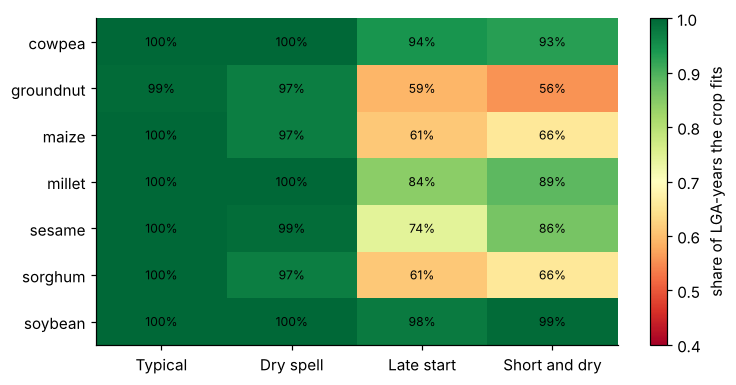

In [9]:
# The same fit share split by A5 season type (2000 to 2024), averaged over LGAs.
by_type = wp.frequency_table(
    all_rows.dropna(subset=["season_type"]), ["lga", "crop", "season_type"]
)
fits = by_type.groupby(["crop", "season_type"])["fits_season_share"].mean().unstack()
fits = fits[["Typical", "Dry spell", "Late start", "Short and dry"]]
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(fits, cmap="RdYlGn", vmin=0.4, vmax=1, aspect="auto")
ax.set_xticks(range(fits.shape[1]), fits.columns)
ax.set_yticks(range(fits.shape[0]), fits.index)
for r in range(fits.shape[0]):
    for c in range(fits.shape[1]):
        ax.text(c, r, f"{fits.iloc[r, c]:.0%}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="share of LGA-years the crop fits")
plt.tight_layout()

## 6. Sensitivity: shallow roots (FAO-56 Table 22 lower bound)

In [10]:
# Sensitivity: rerun with shallow roots (FAO-56 Table 22 lower bounds) and see how much
# more often each crop runs short. A large jump means soil depth matters for that crop.
shallow = {
    "maize": 1.0,
    "sorghum": 1.0,
    "millet": 1.0,
    "soybean": 0.6,
    "cowpea": 0.6,
    "groundnut": 0.5,
    "sesame": 1.0,
}


def short_share_with_roots(name: str, depth_m: float) -> float:
    crop = crops[name].model_copy(update={"root_depth_max_m": depth_m})
    return float(wp.mark_short(wp.run_crop(name, crop, inputs, cfg)[0], share)["ran_short"].mean())


pd.Series(
    {name: short_share_with_roots(name, depth) for name, depth in shallow.items()},
    name="short with shallow roots",
).round(3)

maize        0.016
sorghum      0.015
millet       0.000
soybean      0.018
cowpea       0.003
groundnut    0.112
sesame       0.003
Name: short with shallow roots, dtype: float64

## 7. Check against SMAP root-zone soil moisture (docs/model-evaluation.md)

In [11]:
# Check 1: correlate the bucket's daily root-zone wetness with SMAP soil moisture, per LGA
# (2015 onward). Summary over all 23 LGAs.
smap = pd.read_csv(cfg.paths.smap_daily, parse_dates=["date"])
smap["lga"] = wp.canonical_lga(smap["lga"], inputs.lgas)
years = (cfg.water_balance.smap_years.start, cfg.water_balance.smap_years.end)
check = wp.smap_check(runs[cfg.water_balance.smap_check_crop], smap, years)
check["pearson_r"].describe()[["min", "50%", "max"]].round(3)

min    0.036
50%    0.114
max    0.207
Name: pearson_r, dtype: float64

Weak agreement is expected: in the rainy season the bucket refills to field capacity after most rains, so its wetness barely varies, while SMAP's 0 to 100 cm layer keeps varying. A9 estimates crop need and how often seasons run short, not daily soil moisture.

## 8. Check actual ET against MODIS (MOD16)

Bucket actual ET for maize, summed over calendar months that lie wholly inside the season, beside MODIS actual ET for the same LGA-month. MODIS is a whole-LGA landscape average (crops, bare land, settlements) from an energy-balance model, so it is a check on timing and year-to-year swings more than on level.

In [12]:
# Check 2: bucket actual ET against MODIS MOD16 actual ET per LGA-month, as levels and as
# year-to-year anomalies (each LGA-month's mean removed).
month = pd.read_parquet(cfg.paths.features_dir / "lga_month_features.parquet")
month["lga"] = wp.canonical_lga(month["lga"], inputs.lgas)
et_check = wp.modis_et_check(runs[cfg.water_balance.smap_check_crop], month)
anomaly = et_check.assign(
    bucket=et_check.groupby(["lga", "month"])["bucket_et_mm"].transform(lambda v: v - v.mean()),
    modis=et_check.groupby(["lga", "month"])["modis_et_mm_month"].transform(lambda v: v - v.mean()),
)
et_scores = {
    "LGA-months": len(et_check),
    "mean bucket ET (mm/month)": round(et_check["bucket_et_mm"].mean(), 1),
    "mean MODIS ET (mm/month)": round(et_check["modis_et_mm_month"].mean(), 1),
    "pearson r": round(et_check["bucket_et_mm"].corr(et_check["modis_et_mm_month"]), 3),
    "pearson r of year-to-year anomalies": round(anomaly["bucket"].corr(anomaly["modis"]), 3),
}
et_scores

{'LGA-months': 1842,
 'mean bucket ET (mm/month)': np.float64(103.6),
 'mean MODIS ET (mm/month)': np.float64(71.2),
 'pearson r': np.float64(0.115),
 'pearson r of year-to-year anomalies': np.float64(0.14)}

,bucket_et_mm,modis_et_mm_month
month,,
5,89.7,44.7
6,80.4,50.4
7,107.0,73.4
8,107.6,85.3
9,118.4,74.6
10,122.8,48.0
11,84.2,15.7


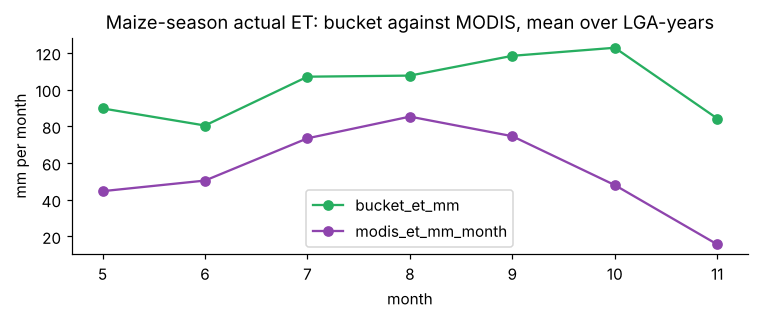

In [13]:
# Seasonal shape of the ET check: mean bucket ET and MODIS ET by calendar month.
by_month = et_check.groupby("month")[["bucket_et_mm", "modis_et_mm_month"]].mean()
ax = by_month.plot(marker="o", figsize=(7, 3), color=["#27ae60", "#8e44ad"])
ax.set_ylabel("mm per month")
ax.set_title("Maize-season actual ET: bucket against MODIS, mean over LGA-years")
plt.tight_layout()
by_month.round(1)

The bucket models a full maize canopy, so it sits above the landscape average, and it keeps rising into September and October while MODIS falls as the landscape dries and crops come off. Year-to-year agreement is weak. MODIS is not used to tune A9; this is recorded as a limit.

## 9. Save the outputs and log the run

In [14]:
# Write the A9 tables (every LGA-year and crop, per-LGA summaries, checks) and the run
# summary, and log the run.
out = cfg.paths.output_dir / "a9"
by_lga = wp.frequency_table(all_rows, ["lga", "crop"]).join(
    hg_rows.groupby(["lga", "crop"])["ran_short"].mean().rename("short_share_hargreaves"),
    on=["lga", "crop"],
)
tables = {
    "a9_lga_year_crop": all_rows,
    "a9_lga_crop_summary": by_lga,
    "a9_lga_crop_season_type": by_type,
    "a9_smap_check": check,
    "a9_modis_et_check": et_check,
}
for name, table in tables.items():
    write_csv(table, out / f"{name}.csv")
summary = {
    **wp.headline(all_rows, by_lga, by_type, check, hg_rows),
    "modis_et_check": et_scores,
    "soil_water_method": soil_method,
}
write_json(summary, out / "a9_summary.json")
log_experiments(cfg.paths.experiment_log, [experiments.a9_row(summary, experiments.today())])
sorted(p.name for p in out.iterdir())

['a9_lga_crop_season_type.csv',
 'a9_lga_crop_summary.csv',
 'a9_lga_year_crop.csv',
 'a9_modis_et_check.csv',
 'a9_smap_check.csv',
 'a9_summary.json']